### Пример реализации метода конечных разностей (МКР) для решения уравнения Пуассона: $\Delta\psi(r) = f(r)$. В 1D получаем  $\frac{\partial^2\psi}{\partial x^2} = f(x)$

Ошибка: 0.00205870676453479


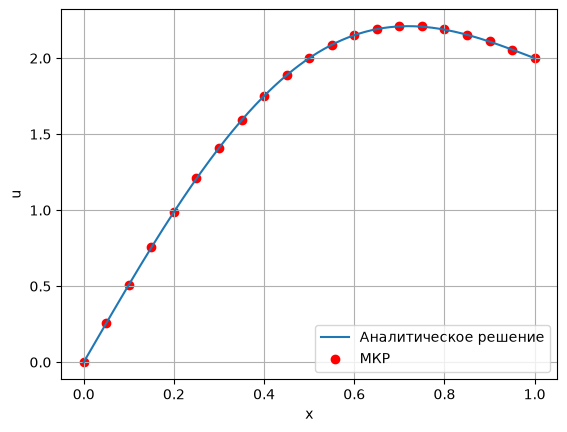

Период сетки = 0.100000, Ошибка = 0.008265
Период сетки = 0.050000, Ошибка = 0.002059
Период сетки = 0.025000, Ошибка = 0.000514
Период сетки = 0.012500, Ошибка = 0.000129
Период сетки = 0.006250, Ошибка = 0.000032
Период сетки = 0.003125, Ошибка = 0.000008
Период сетки = 0.001563, Ошибка = 0.000002
Период сетки = 0.000781, Ошибка = 0.000001


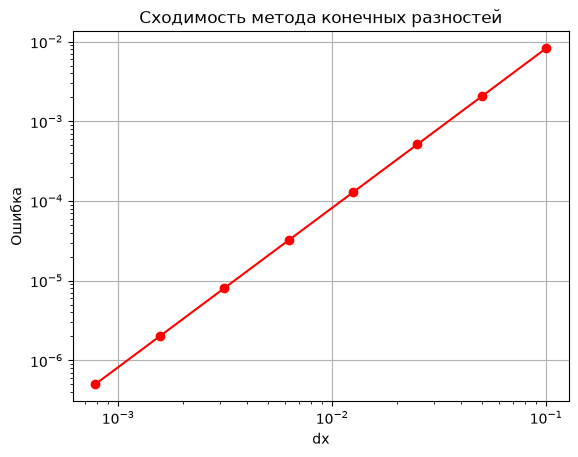

In [39]:
import numpy as np
import matplotlib.pyplot as plt

Lx = 1.0
u_bottom, u_top = 0.0, 2.0


def f(x):
    return -np.pi**2 * np.sin(np.pi * x)

 
def u_ref(x):
    return np.sin(np.pi * x) + u_bottom + (u_top - u_bottom) * x / Lx


def solve_poisson(dx):
    """
    Решает u'' = f(x) на [0, Lx] с условиями Дирихле
    u(0) = u_bottom, u(Lx) = u_top методом конечных разностей.

    dx — желаемый шаг сетки. Если Lx не делится на dx нацело, шаг
    слегка корректируется, чтобы сетка точно попала в конец отрезка.

    Возвращает узлы сетки x и численное решение u.
    """
    Nx = int(round(Lx / dx))      # число интервалов

    x = np.linspace(0, Lx, Nx + 1)
    dx = Lx / Nx                  # фактический шаг сетки

    # Матрица для внутренних узлов (размер Nx-1)
    n = Nx - 1
    A = (np.diag(-2 * np.ones(n))
         + np.diag(np.ones(n - 1), 1)
         + np.diag(np.ones(n - 1), -1)) / dx**2

    # Правая часть с учётом граничных условий
    b = f(x[1:-1])
    b[0] -= u_bottom / dx**2
    b[-1] -= u_top / dx**2

    # Решение СЛАУ
    u = np.empty(Nx + 1)
    u[0], u[-1] = u_bottom, u_top
    u[1:-1] = np.linalg.solve(A, b)
    return x, u


# Решение для одного шага + график
x, u = solve_poisson(dx=0.05)
print("Ошибка:", np.max(np.abs(u - u_ref(x))))

x_ref = np.linspace(0, Lx, 300)
plt.plot(x_ref, u_ref(x_ref), label="Аналитическое решение")
plt.scatter(x, u, label="МКР", color="red")
plt.xlabel("x")
plt.ylabel("u")
plt.legend()
plt.grid()
plt.show()



# Сходимость при уменьшении шага
dx_array = []
error_array = []

for dx in [0.1, 0.05, 0.025, 0.0125, 0.00625, 0.003125, 0.0015625, 0.00078125]:
    x, u = solve_poisson(dx)
    print(f"Период сетки = {dx:1.6f}, Ошибка = {np.max(np.abs(u - u_ref(x))):1.6f}")
    dx_array.append(dx)
    error_array.append(np.max(np.abs(u - u_ref(x))))

plt.loglog(dx_array, error_array, "ro-")
plt.xlabel("dx")
plt.ylabel("Ошибка")
plt.title("Сходимость метода конечных разностей")
plt.grid()
plt.show()

